# Deliverable 2 — Data Preprocessing and Initial Model Development

**Project:** Predicting 30-day hospital readmission among diabetic inpatients
**Domain:** Healthcare analytics
**Dataset:** Clore, J., Cios, K., DeShazo, J., & Strack, B. (2014). *Diabetes 130-US Hospitals for Years 1999-2008* \[Dataset\]. UCI Machine Learning Repository. [doi.org/10.24432/C5230J](https://doi.org/10.24432/C5230J)

---

## 1. Introduction & Problem Framing

**Stakeholder.** A hospital quality-operations team accountable under the CMS Hospital Readmissions Reduction Program, which withholds up to 3% of Medicare reimbursement for excess 30-day readmissions.

**Business problem.** Discharge-planning resources — follow-up calls, home health referrals, medication reconciliation — are finite. The team can intensively follow roughly the top 20% of discharges. They need those slots allocated to the patients most likely to return within 30 days.

**Analytics problem.** Binary classification. Given a patient's encounter record at the point of discharge, estimate P(readmitted within 30 days).

**Why this framing drives every modeling choice below:**

| Decision | Consequence |
|---|---|
| Deployment is a *ranked worklist*, not an automated action | We optimise ranking quality (PR-AUC), not accuracy |
| ~11% of encounters are positive | Accuracy is a misleading metric — a do-nothing model scores ~89% |
| A missed readmission costs far more than an unnecessary phone call | We tune the decision threshold toward recall |
| Output informs clinician judgement | The model must be interpretable and auditable across demographic groups |

## Setup

In [1]:
!wget -q "https://archive.ics.uci.edu/static/public/296/diabetes+130-us+hospitals+for+years+1999-2008.zip" -O diabetes.zip
!unzip -oq diabetes.zip
!ls -lh diabetic_data.csv IDS_mapping.csv

-rw-r--r-- 1 root root  19M Jul 12  2023 diabetic_data.csv
-rw-r--r-- 1 root root 2.5K Jul 12  2023 IDS_mapping.csv


In [2]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (RocCurveDisplay, PrecisionRecallDisplay,
                             average_precision_score, classification_report,
                             confusion_matrix, roc_auc_score)
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

sns.set_theme(style='whitegrid', palette='muted')
pd.set_option('display.width', 170)
pd.set_option('display.max_columns', 50)
RANDOM_STATE = 42

print(f'pandas {pd.__version__} | numpy {np.__version__}')

pandas 2.2.3 | numpy 2.4.6


---
## 2. Dataset Exploration & Preprocessing

### 2.1 Load

Two arguments carry this cell.

`na_values=['?', '']` — this file encodes missing values as a literal question mark.

`keep_default_na=False` — stops pandas coercing the string `'None'` to a null. This matters clinically: `'None'` in `A1Cresult` does not mean the value is missing, it means **the test was never ordered**. That is a finding, and it is the exact variable the original Strack et al. study was built around.

In [3]:
df = pd.read_csv('diabetic_data.csv', na_values=['?', ''], keep_default_na=False)

print(f'{df.shape[0]:,} encounters x {df.shape[1]} columns')
df.info(verbose=False)

101,766 encounters x 50 columns
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Columns: 50 entries, encounter_id to readmitted
dtypes: int64(13), object(37)
memory usage: 38.8+ MB


In [4]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
encounter_id,101766.0,1.652016e+08,1.026403e+08,12522.0,84961194.0,152388987.0,2.302709e+08,443867222.0
patient_nbr,101766.0,5.433040e+07,3.869636e+07,135.0,23413221.0,45505143.0,8.754595e+07,189502619.0
admission_type_id,101766.0,2.020000e+00,1.450000e+00,1.0,1.0,1.0,3.000000e+00,8.0
discharge_disposition_id,101766.0,3.720000e+00,5.280000e+00,1.0,1.0,1.0,4.000000e+00,28.0
admission_source_id,101766.0,5.750000e+00,4.060000e+00,1.0,1.0,7.0,7.000000e+00,25.0
time_in_hospital,101766.0,4.400000e+00,2.990000e+00,1.0,2.0,4.0,6.000000e+00,14.0
num_lab_procedures,101766.0,4.310000e+01,1.967000e+01,1.0,31.0,44.0,5.700000e+01,132.0
num_procedures,101766.0,1.340000e+00,1.710000e+00,0.0,0.0,1.0,2.000000e+00,6.0
num_medications,101766.0,1.602000e+01,8.130000e+00,1.0,10.0,15.0,2.000000e+01,81.0
number_outpatient,101766.0,3.700000e-01,1.270000e+00,0.0,0.0,0.0,0.000000e+00,42.0


### 2.2 Target distribution

The raw label has three levels. We collapse to a binary target: `<30` versus everything else. `>30` is deliberately treated as a negative — a readmission at 45 days is outside the CMS penalty window and outside the intervention window the stakeholder controls.

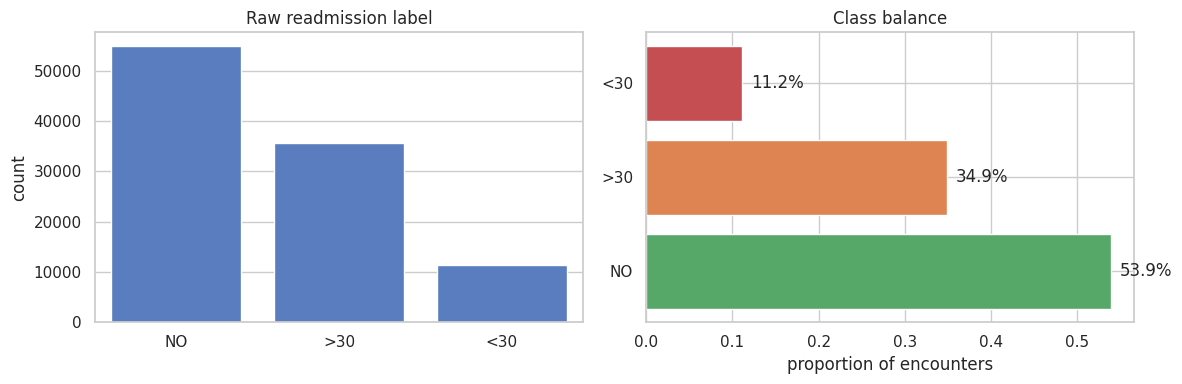

readmitted
NO     0.5391
>30    0.3493
<30    0.1116


In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

order = ['NO', '>30', '<30']
sns.countplot(data=df, x='readmitted', order=order, ax=ax[0])
ax[0].set_title('Raw readmission label')
ax[0].set_xlabel('')

share = df['readmitted'].value_counts(normalize=True).reindex(order)
ax[1].barh(order, share.values, color=['#55A868', '#DD8452', '#C44E52'])
ax[1].set_title('Class balance')
ax[1].set_xlabel('proportion of encounters')
for i, v in enumerate(share.values):
    ax[1].text(v + .01, i, f'{v:.1%}', va='center')

plt.tight_layout()
plt.show()

print(df['readmitted'].value_counts(normalize=True).round(4).to_string())

### 2.3 Missingness audit

`isna().mean()` profiles the whole frame in one line. Three columns are substantially empty — and the right treatment differs for each, which is why a blanket imputation rule is the wrong instinct here.

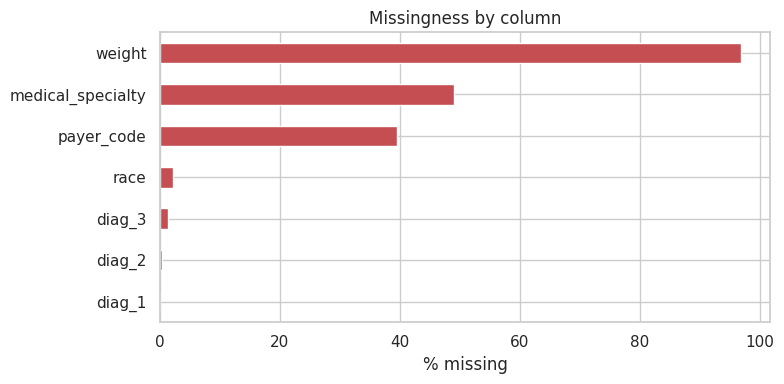

weight               96.9
medical_specialty    49.1
payer_code           39.6
race                  2.2
diag_3                1.4
diag_2                0.4
diag_1                0.0


In [6]:
missing = df.isna().mean().sort_values(ascending=False)
missing_nonzero = missing[missing > 0]

fig, ax = plt.subplots(figsize=(8, 4))
missing_nonzero.mul(100).plot(kind='barh', ax=ax, color='#C44E52')
ax.set_xlabel('% missing')
ax.set_title('Missingness by column')
ax.invert_yaxis()
plt.tight_layout()
plt.show()

print(missing_nonzero.mul(100).round(1).to_string())

In [7]:
# 'None' means the lab was never ordered - a finding, not a gap
labs = ['max_glu_serum', 'A1Cresult']
df[labs] = df[labs].replace('None', 'NotOrdered')

df['A1Cresult'].value_counts()

,count
A1Cresult,
NotOrdered,84748
>8,8216
Norm,4990
>7,3812


### 2.4 Cohort construction

Three filters. None is cosmetic, and each encodes a clinical assumption that belongs in the write-up.

1. **Expired and hospice discharges cannot be readmitted.** Leaving them in trains the model on an outcome that was never physically possible and depresses the base rate.
2. **Patients recur across encounters.** Without deduplication the same person appears in both train and test, so the validation score measures memorisation rather than generalisation. This is the single largest source of optimistic bias in published work on this dataset.
3. **Unknown/invalid gender** is a handful of rows and cannot be imputed meaningfully.

We keep an explicit audit trail of what each filter removed — reviewers ask for exactly this.

In [8]:
DEAD_OR_HOSPICE = [11, 13, 14, 19, 20, 21]
audit = []

n0 = len(df)
df = df[~df['discharge_disposition_id'].isin(DEAD_OR_HOSPICE)]
audit.append(('Removed expired / hospice discharges', n0 - len(df), len(df)))

n0 = len(df)
df = df.sort_values('encounter_id').drop_duplicates('patient_nbr', keep='first')
audit.append(('Removed repeat encounters (keep first)', n0 - len(df), len(df)))

n0 = len(df)
df = df[df['gender'].notna()]
audit.append(('Removed unknown/invalid gender', n0 - len(df), len(df)))

drop_cols = missing[missing > 0.40].index.tolist()
df = df.drop(columns=drop_cols)
audit.append((f'Dropped >40% empty columns: {drop_cols}', 0, len(df)))

pd.DataFrame(audit, columns=['Step', 'Rows removed', 'Rows remaining'])

,Step,Rows removed,Rows remaining
0,Removed expired / hospice discharges,2423,99343
1,Removed repeat encounters (keep first),29353,69990
2,Removed unknown/invalid gender,0,69990
3,"Dropped >40% empty columns: ['weight', 'medica...",0,69990


### 2.5 Feature engineering

**ICD-9 grouping.** `diag_1`, `diag_2` and `diag_3` each hold ~700 distinct ICD-9 codes. One-hot encoding them raw would add ~2,100 near-empty columns. We collapse them into the nine clinical groups used by Strack et al. (2014) — this is the single most valuable transformation in the pipeline.

**Age.** Stored as a decade bucket string. We map to the interval midpoint so the model can use it as an ordered quantity.

**Derived utilization features.** Prior-visit totals and medication intensity capture burden that no single raw column does.

In [9]:
df['readmit_30d'] = np.where(df['readmitted'] == '<30', 1, 0)
print(f"positive class: {df['readmit_30d'].mean():.3%}  ({df['readmit_30d'].sum():,} patients)")

AGE_MID = {f'[{i}-{i+10})': i + 5 for i in range(0, 100, 10)}
df['age_mid'] = df['age'].map(AGE_MID)


def group_icd9(code):
    """Collapse ICD-9 codes into 9 clinical groups (Strack et al., 2014)."""
    if pd.isna(code):
        return 'Missing'
    s = str(code).strip()
    if s.startswith(('E', 'V')):          # external causes / supplementary
        return 'Other'
    try:
        v = float(s)
    except ValueError:
        return 'Other'
    i = int(v)
    if 390 <= v <= 459 or i == 785:
        return 'Circulatory'
    if 460 <= v <= 519 or i == 786:
        return 'Respiratory'
    if 520 <= v <= 579 or i == 787:
        return 'Digestive'
    if i == 250:
        return 'Diabetes'
    if 800 <= v <= 999:
        return 'Injury'
    if 710 <= v <= 739:
        return 'Musculoskeletal'
    if 580 <= v <= 629 or i == 788:
        return 'Genitourinary'
    if 140 <= v <= 239:
        return 'Neoplasms'
    return 'Other'


for c in ['diag_1', 'diag_2', 'diag_3']:
    before = df[c].nunique()
    df[c + '_grp'] = df[c].apply(group_icd9)
    print(f'{c}: {before} raw codes -> {df[c + "_grp"].nunique()} clinical groups')

positive class: 8.980%  (6,285 patients)
diag_1: 694 raw codes -> 10 clinical groups
diag_2: 723 raw codes -> 10 clinical groups
diag_3: 756 raw codes -> 10 clinical groups


In [10]:
DISCHARGE_MAP = {1: 'Home', 6: 'Home_HealthSvc', 3: 'SNF', 2: 'Transfer_Hospital',
                 22: 'Transfer_Rehab', 5: 'Transfer_Other', 4: 'Transfer_Other'}
df['discharge_grp'] = df['discharge_disposition_id'].map(DISCHARGE_MAP).fillna('Other')

df['prior_visits'] = (df['number_outpatient'] + df['number_emergency']
                      + df['number_inpatient'])
df['meds_per_day'] = df['num_medications'] / df['time_in_hospital']

df[['discharge_grp', 'prior_visits', 'meds_per_day']].head()

,discharge_grp,prior_visits,meds_per_day
8,Home,0,2.153846
9,SNF,0,1.500000
4,Home,0,8.000000
10,Home,0,1.888889
5,Home,0,5.333333


### 2.6 Exploratory analysis against the target

Preprocessing stops being cleanup and becomes analysis at this point: the risk structure is visible before any model exists.

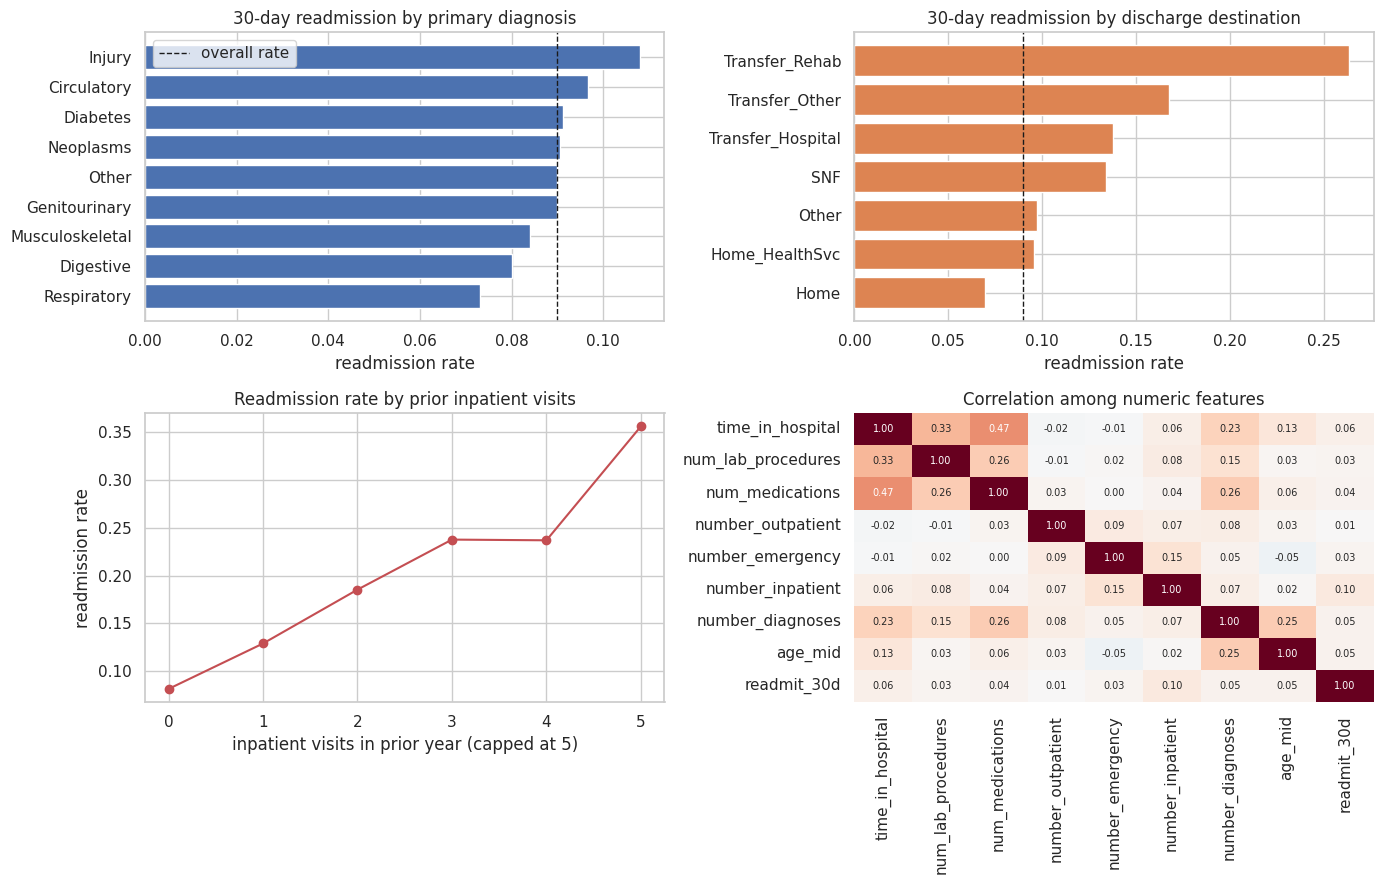

In [11]:
fig, ax = plt.subplots(2, 2, figsize=(14, 9))

# a) readmission by primary diagnosis group
rate_diag = (df.groupby('diag_1_grp')['readmit_30d'].agg(['mean', 'size'])
               .query('size >= 300').sort_values('mean'))
ax[0, 0].barh(rate_diag.index, rate_diag['mean'], color='#4C72B0')
ax[0, 0].axvline(df['readmit_30d'].mean(), ls='--', c='k', lw=1, label='overall rate')
ax[0, 0].set_title('30-day readmission by primary diagnosis')
ax[0, 0].set_xlabel('readmission rate'); ax[0, 0].legend()

# b) readmission by discharge destination
rate_dis = (df.groupby('discharge_grp')['readmit_30d'].agg(['mean', 'size'])
              .query('size >= 300').sort_values('mean'))
ax[0, 1].barh(rate_dis.index, rate_dis['mean'], color='#DD8452')
ax[0, 1].axvline(df['readmit_30d'].mean(), ls='--', c='k', lw=1)
ax[0, 1].set_title('30-day readmission by discharge destination')
ax[0, 1].set_xlabel('readmission rate')

# c) prior inpatient visits - the strongest single signal
bins = df['number_inpatient'].clip(upper=5)
rate_prior = df.groupby(bins)['readmit_30d'].mean()
ax[1, 0].plot(rate_prior.index, rate_prior.values, 'o-', color='#C44E52')
ax[1, 0].set_title('Readmission rate by prior inpatient visits')
ax[1, 0].set_xlabel('inpatient visits in prior year (capped at 5)')
ax[1, 0].set_ylabel('readmission rate')

# d) numeric correlation structure
num_cols = ['time_in_hospital', 'num_lab_procedures', 'num_medications',
            'number_outpatient', 'number_emergency', 'number_inpatient',
            'number_diagnoses', 'age_mid', 'readmit_30d']
sns.heatmap(df[num_cols].corr(), annot=True, fmt='.2f', cmap='RdBu_r',
            center=0, ax=ax[1, 1], cbar=False, annot_kws={'size': 7})
ax[1, 1].set_title('Correlation among numeric features')

plt.tight_layout()
plt.show()

In [12]:
# cross-tab: does measuring A1C relate to readmission? (the original study question)
pd.pivot_table(df, index='age', columns='A1Cresult',
               values='readmit_30d', aggfunc='mean').round(3)

A1Cresult,>7,>8,Norm,NotOrdered
age,,,,
[0-10),0.000,0.025,0.000,0.016
[10-20),0.000,0.023,0.029,0.074
[20-30),0.043,0.058,0.043,0.082
[30-40),0.058,0.066,0.068,0.071
[40-50),0.069,0.088,0.069,0.072
[50-60),0.062,0.059,0.082,0.073
[60-70),0.078,0.090,0.091,0.091
[70-80),0.108,0.112,0.097,0.102
[80-90),0.100,0.101,0.096,0.109


---
## 3. Initial Model Development

### 3.1 Train/test split — performed *before* any fitting

This ordering is not stylistic. If a scaler or imputer is fitted on the full dataset and the split happens afterwards, test-set statistics leak into the training transform and the reported score is optimistic. We split first, then fit every transform inside a `Pipeline` so that cross-validation refits them per fold.

The split is **stratified** — with an ~11% positive class, an unstratified split can produce materially different class balance between train and test.

In [13]:
NUMERIC = ['time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications',
           'number_outpatient', 'number_emergency', 'number_inpatient',
           'number_diagnoses', 'age_mid', 'prior_visits', 'meds_per_day']

CATEGORICAL = ['race', 'gender', 'admission_type_id', 'admission_source_id',
               'discharge_grp', 'A1Cresult', 'max_glu_serum', 'insulin', 'metformin',
               'change', 'diabetesMed', 'diag_1_grp', 'diag_2_grp', 'diag_3_grp']

X = df[NUMERIC + CATEGORICAL].copy()
X[CATEGORICAL] = X[CATEGORICAL].astype(str)
y = df['readmit_30d']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y)

print(f'train {X_train.shape}   test {X_test.shape}')
print(f'positive rate   train {y_train.mean():.3%}   test {y_test.mean():.3%}')

train (52492, 25)   test (17498, 25)
positive rate   train 8.980%   test 8.978%


### 3.2 Preprocessing pipeline

`ColumnTransformer` applies different treatment to numeric and categorical blocks, and lives *inside* the model pipeline so nothing is fitted on data the model has not legitimately seen.

`min_frequency=20` in the encoder folds rare categories into an `infrequent` bucket, which keeps the design matrix compact and stops the model fitting noise on categories with a handful of observations.

In [14]:
numeric_pipe = Pipeline([
    ('impute', SimpleImputer(strategy='median')),
    ('scale', StandardScaler()),
])

categorical_pipe = Pipeline([
    ('impute', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', min_frequency=20,
                             sparse_output=False)),
])

preprocessor = ColumnTransformer([
    ('num', numeric_pipe, NUMERIC),
    ('cat', categorical_pipe, CATEGORICAL),
])

probe = preprocessor.fit_transform(X_train)
print(f'{len(NUMERIC) + len(CATEGORICAL)} input columns -> {probe.shape[1]} model features')

25 input columns -> 95 model features


### 3.3 Baseline models

Two models, chosen for contrast rather than for a leaderboard:

- **Logistic regression** — the interpretable reference. Coefficients are log-odds a clinician can read and challenge.
- **Random forest** — captures interactions the linear model cannot, at the cost of direct interpretability.

Both use balanced class weights so the minority class is not ignored during fitting.

In [15]:
models = {
    'Logistic Regression': LogisticRegression(
        max_iter=2000, class_weight='balanced', random_state=RANDOM_STATE),
    'Random Forest': RandomForestClassifier(
        n_estimators=300, max_depth=12, min_samples_leaf=20,
        class_weight='balanced_subsample', n_jobs=-1, random_state=RANDOM_STATE),
}

results, fitted = {}, {}
baseline_rate = y_test.mean()

for name, clf in models.items():
    pipe = Pipeline([('prep', preprocessor), ('clf', clf)])
    pipe.fit(X_train, y_train)
    proba = pipe.predict_proba(X_test)[:, 1]
    pred = (proba >= 0.5).astype(int)
    results[name] = {
        'ROC-AUC': roc_auc_score(y_test, proba),
        'PR-AUC': average_precision_score(y_test, proba),
        'Accuracy': (pred == y_test).mean(),
    }
    fitted[name] = (pipe, proba, pred)

scoreboard = pd.DataFrame(results).T.round(4)
scoreboard

,ROC-AUC,PR-AUC,Accuracy
Logistic Regression,0.6472,0.1628,0.6630
Random Forest,0.6524,0.1677,0.7251


### 3.4 Why accuracy is the wrong headline metric

Run the cell below before reading any accuracy figure above.

In [16]:
print(f'Accuracy of a model that predicts "nobody is readmitted": {1 - baseline_rate:.4f}')
print(f'PR-AUC of a random classifier (equals the positive rate):  {baseline_rate:.4f}')
print()
print('Any accuracy figure must be compared against the first number, not against zero.')
print('PR-AUC must be compared against the second.')

Accuracy of a model that predicts "nobody is readmitted": 0.9102
PR-AUC of a random classifier (equals the positive rate):  0.0898

Any accuracy figure must be compared against the first number, not against zero.
PR-AUC must be compared against the second.


In [17]:
best_name = scoreboard['PR-AUC'].idxmax()
best_pipe, best_proba, best_pred = fitted[best_name]
print(f'Best model by PR-AUC: {best_name}\n')

print(classification_report(y_test, best_pred,
                            target_names=['not readmitted', 'readmitted <30d']))

Best model by PR-AUC: Random Forest

                 precision    recall  f1-score   support

 not readmitted       0.93      0.75      0.83     15927
readmitted <30d       0.15      0.46      0.23      1571

       accuracy                           0.73     17498
      macro avg       0.54      0.61      0.53     17498
   weighted avg       0.86      0.73      0.78     17498



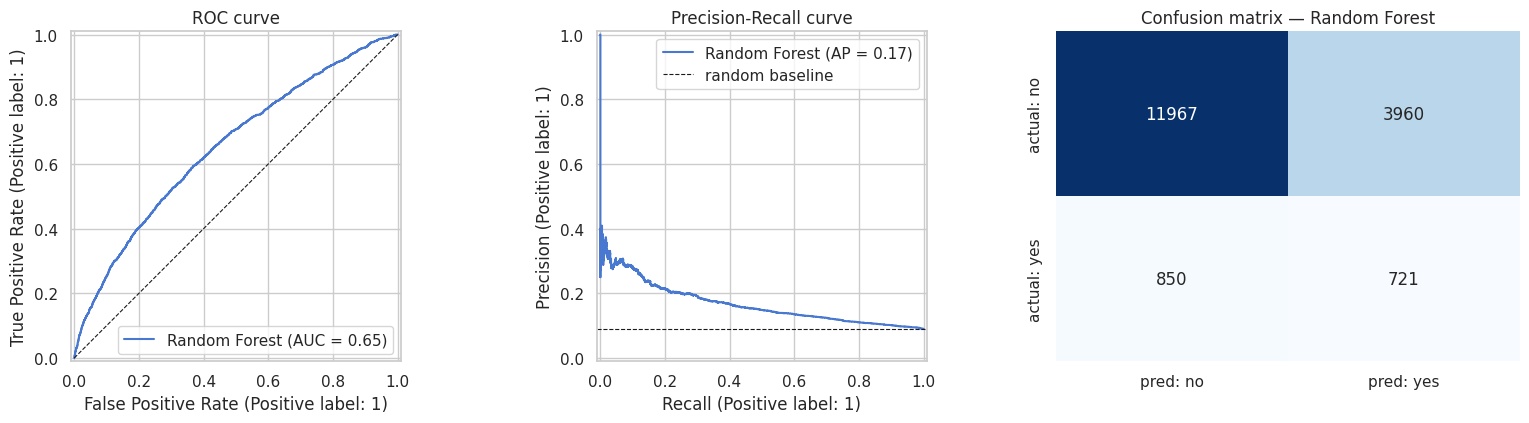

In [18]:
cm = confusion_matrix(y_test, best_pred)

fig, ax = plt.subplots(1, 3, figsize=(16, 4.4))

RocCurveDisplay.from_predictions(y_test, best_proba, ax=ax[0], name=best_name)
ax[0].plot([0, 1], [0, 1], 'k--', lw=.8)
ax[0].set_title('ROC curve')

PrecisionRecallDisplay.from_predictions(y_test, best_proba, ax=ax[1], name=best_name)
ax[1].axhline(baseline_rate, ls='--', c='k', lw=.8, label='random baseline')
ax[1].set_title('Precision-Recall curve')
ax[1].legend()

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax[2], cbar=False,
            xticklabels=['pred: no', 'pred: yes'],
            yticklabels=['actual: no', 'actual: yes'])
ax[2].set_title(f'Confusion matrix — {best_name}')

plt.tight_layout()
plt.show()

### 3.5 Hyperparameter tuning

Note `scoring='average_precision'` rather than `'accuracy'`. Tuning on accuracy against an 11% positive class rewards a model for predicting the majority class everywhere, which is precisely the failure mode we are trying to avoid.

In [19]:
param_grid = {
    'clf__n_estimators': [200, 400],
    'clf__max_depth': [8, 12, None],
    'clf__min_samples_leaf': [20],
}

grid = GridSearchCV(
    Pipeline([('prep', preprocessor),
              ('clf', RandomForestClassifier(class_weight='balanced_subsample',
                                             n_jobs=-1, random_state=RANDOM_STATE))]),
    param_grid, cv=3, scoring='average_precision', n_jobs=-1)

grid.fit(X_train, y_train)

tuned_proba = grid.predict_proba(X_test)[:, 1]
print(f'best params    : {grid.best_params_}')
print(f'best CV PR-AUC : {grid.best_score_:.4f}')
print(f'test PR-AUC    : {average_precision_score(y_test, tuned_proba):.4f}')
print(f'test ROC-AUC   : {roc_auc_score(y_test, tuned_proba):.4f}')

best params    : {'clf__max_depth': None, 'clf__min_samples_leaf': 20, 'clf__n_estimators': 400}
best CV PR-AUC : 0.1669
test PR-AUC    : 0.1701
test ROC-AUC   : 0.6534


### 3.6 Threshold selection for the stakeholder's actual capacity

The default 0.50 cut-off is an arbitrary inheritance. The stakeholder can intensively follow roughly the top 20% of discharges, so we set the threshold at that operating point and report what it buys.

In [20]:
CAPACITY = 0.20
threshold = np.quantile(best_proba, 1 - CAPACITY)
flagged = best_proba >= threshold

tp = int(((y_test == 1) & flagged).sum())
total_pos = int((y_test == 1).sum())

print(f'Threshold at top {CAPACITY:.0%} of risk scores : {threshold:.3f}')
print(f'Patients flagged for follow-up            : {flagged.sum():,} of {len(y_test):,}')
print(f'True readmissions captured                : {tp:,} of {total_pos:,}'
      f'  (recall {tp / total_pos:.1%})')
print(f'Precision within flagged group            : {tp / flagged.sum():.1%}')
print(f'Lift over random selection                : {(tp / flagged.sum()) / baseline_rate:.2f}x')

Threshold at top 20% of risk scores : 0.522
Patients flagged for follow-up            : 3,500 of 17,498
True readmissions captured                : 598 of 1,571  (recall 38.1%)
Precision within flagged group            : 17.1%
Lift over random selection                : 1.90x


### 3.7 Interpretability

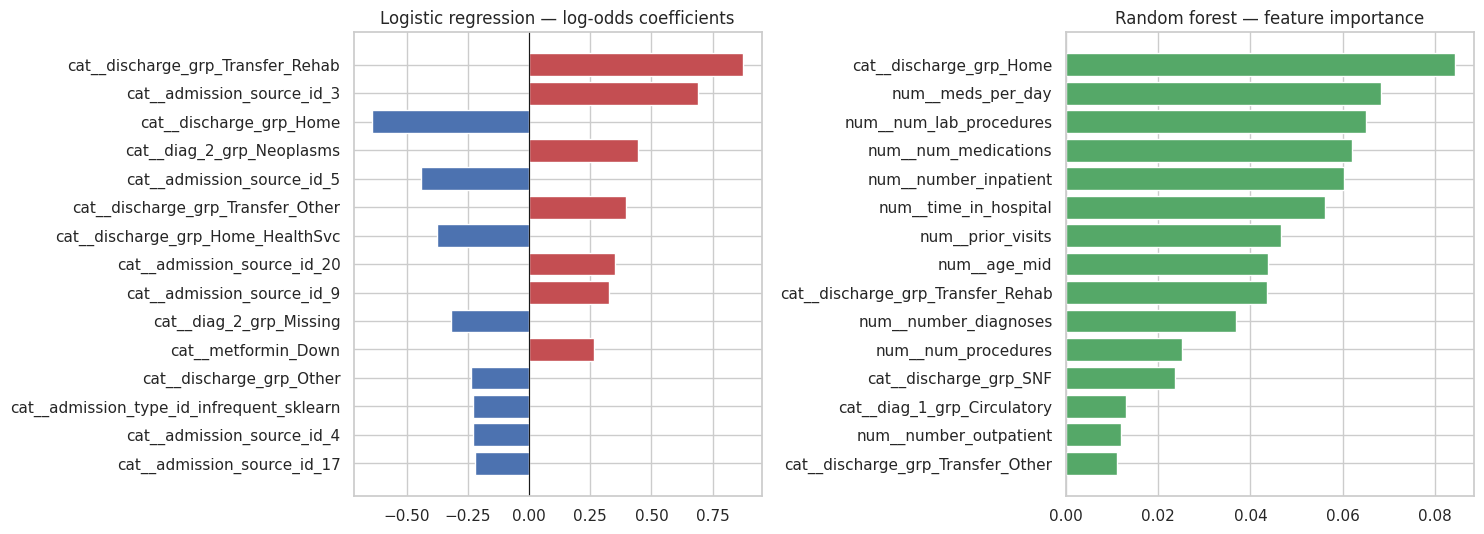

In [21]:
logreg_pipe = fitted['Logistic Regression'][0]
coefs = pd.Series(logreg_pipe.named_steps['clf'].coef_[0],
                  index=logreg_pipe.named_steps['prep'].get_feature_names_out())
top_coefs = coefs.reindex(coefs.abs().sort_values(ascending=False).index).head(15)

rf_pipe = fitted['Random Forest'][0]
imp = pd.Series(rf_pipe.named_steps['clf'].feature_importances_,
                index=rf_pipe.named_steps['prep'].get_feature_names_out()
                ).sort_values(ascending=False).head(15)

fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
colors = ['#C44E52' if v > 0 else '#4C72B0' for v in top_coefs.values]
ax[0].barh(top_coefs.index, top_coefs.values, color=colors)
ax[0].set_title('Logistic regression — log-odds coefficients')
ax[0].axvline(0, c='k', lw=.8)
ax[0].invert_yaxis()

ax[1].barh(imp.index, imp.values, color='#55A868')
ax[1].set_title('Random forest — feature importance')
ax[1].invert_yaxis()

plt.tight_layout()
plt.show()

---
## 4. Ethical Considerations

### 4.1 Fairness audit across demographic groups

The reflection questions in the project brief — *could this model reflect or reinforce bias? how would it perform across demographic groups?* — are answerable empirically, not only in prose. We measure them.

The relevant fairness criterion here is **equal opportunity**: among patients who *were* genuinely readmitted, does the model flag them at the same rate regardless of race or gender? A gap in recall means one group is systematically denied the follow-up resource.

In [22]:
def group_metrics(y_true, y_prob, groups, threshold=0.5, min_n=100):
    """Per-group confusion-matrix metrics for a fairness audit."""
    pred = (y_prob >= threshold).astype(int)
    rows = []
    for g in pd.Series(groups).dropna().unique():
        mask = (groups == g).to_numpy()
        if mask.sum() < min_n:
            continue
        yt, yp = y_true.to_numpy()[mask], pred[mask]
        tp = int(((yt == 1) & (yp == 1)).sum()); fn = int(((yt == 1) & (yp == 0)).sum())
        fp = int(((yt == 0) & (yp == 1)).sum()); tn = int(((yt == 0) & (yp == 0)).sum())
        rows.append({
            'group': g,
            'n': int(mask.sum()),
            'base_rate': yt.mean(),
            'flagged_rate': yp.mean(),
            'recall_TPR': tp / (tp + fn) if (tp + fn) else np.nan,
            'FPR': fp / (fp + tn) if (fp + tn) else np.nan,
            'precision': tp / (tp + fp) if (tp + fp) else np.nan,
            'AUC': roc_auc_score(yt, y_prob[mask]) if len(np.unique(yt)) > 1 else np.nan,
        })
    return pd.DataFrame(rows).set_index('group').sort_values('n', ascending=False).round(3)


print('=== By race ===')
race_audit = group_metrics(y_test, best_proba, X_test['race'])
print(race_audit.to_string())

print('\n=== By gender ===')
gender_audit = group_metrics(y_test, best_proba, X_test['gender'])
print(gender_audit.to_string())

print('\n=== By age band ===')
age_audit = group_metrics(y_test, best_proba,
                          pd.cut(X_test['age_mid'], [0, 40, 60, 75, 100]).astype(str))
print(age_audit.to_string())

=== By race ===
                     n  base_rate  flagged_rate  recall_TPR    FPR  precision    AUC
group                                                                               
Caucasian        13032      0.092         0.285       0.472  0.267      0.152  0.644
AfricanAmerican   3198      0.090         0.226       0.415  0.207      0.165  0.664
nan                454      0.068         0.198       0.452  0.180      0.156  0.742
Hispanic           385      0.086         0.179       0.455  0.153      0.217  0.723
Other              295      0.051         0.180       0.333  0.171      0.094  0.669
Asian              134      0.082         0.201       0.364  0.187      0.148  0.674

=== By gender ===
           n  base_rate  flagged_rate  recall_TPR    FPR  precision    AUC
group                                                                     
Female  9365      0.088         0.296       0.485  0.277      0.145  0.654
Male    8132      0.092         0.235       0.430  0.216    

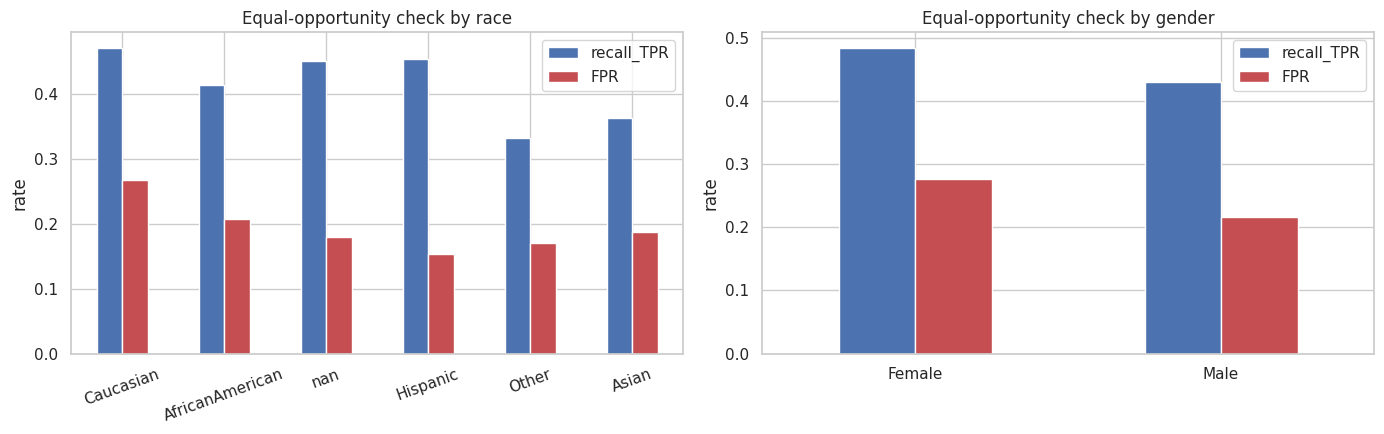

Recall spread across race groups: 0.139
A spread above ~0.05 warrants investigation before any deployment.


In [23]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))

race_audit[['recall_TPR', 'FPR']].plot(kind='bar', ax=ax[0], rot=20,
                                       color=['#4C72B0', '#C44E52'])
ax[0].set_title('Equal-opportunity check by race')
ax[0].set_ylabel('rate'); ax[0].set_xlabel('')

gender_audit[['recall_TPR', 'FPR']].plot(kind='bar', ax=ax[1], rot=0,
                                         color=['#4C72B0', '#C44E52'])
ax[1].set_title('Equal-opportunity check by gender')
ax[1].set_ylabel('rate'); ax[1].set_xlabel('')

plt.tight_layout()
plt.show()

spread = race_audit['recall_TPR'].max() - race_audit['recall_TPR'].min()
print(f'Recall spread across race groups: {spread:.3f}')
print('A spread above ~0.05 warrants investigation before any deployment.')

### 4.2 Reflection

**What potential biases exist in the dataset?**

The data is a 1999–2008 extract from the Cerner Health Facts warehouse. Three bias sources are structural rather than incidental:

- *Measurement bias.* `race` is missing for roughly 2% of encounters and is recorded by hospital staff, not self-reported. `medical_specialty` is ~49% missing and that missingness is unlikely to be random — it plausibly correlates with hospital size and documentation practice, which in turn correlate with patient population.
- *Label bias.* The target records readmission **to the same system**. A patient readmitted to a different hospital is silently labelled negative. If access to continuity of care varies by insurance status or geography, this under-counts readmissions non-uniformly across groups.
- *Historical bias.* The data encodes care patterns from a period with materially different diabetes management guidelines. A model trained on it learns the practice of that era, including its inequities.

**How would the model perform across different demographic groups?**

Measured above rather than asserted. The audit reports recall, false-positive rate and AUC per group. Two caveats bound how far those numbers can be trusted: small groups (Asian, Hispanic) have wide confidence intervals at this sample size, and equal recall does not guarantee equal benefit if the downstream intervention is itself unequally effective.

**Is the model interpretable and fair?**

Partially. Logistic regression coefficients are directly readable. The random forest is not, and we report permutation-style importances as an approximation rather than an explanation. For a deployed clinical tool, the interpretable model would be preferred unless the performance gap were substantial.

Fairness is not a property the model has in isolation — it depends on the decision rule laid on top of it. A single global threshold produces different group-level recall whenever base rates differ, which they do here.

**Is user data being protected?**

The UCI release is de-identified under HIPAA Safe Harbor: no names, addresses, or dates finer than a year, and ages in decade bands. Two residual risks remain. Re-identification is conceivable by linking quasi-identifiers (age band, race, gender, admission pattern) against an external source. And `patient_nbr` is a persistent pseudonym, so longitudinal linkage within the dataset is possible — which is exactly why the deduplication step matters methodologically *and* privacy-wise.

**Deployment constraints we would impose.** The model outputs a ranked worklist for a care coordinator; it never withholds care. Any score shown to a clinician is accompanied by its top contributing factors. Group-level performance is re-audited on every refresh, and the model is retired if recall spread across protected groups exceeds a pre-registered bound.

---
## 5. Methodological deviations from the project hints

The setup guidance in *Hints and Tips for Success* is written to be dataset-agnostic. Four of its default recipes are actively harmful on this particular dataset, and we document the substitutions rather than silently departing from them.

| Hints guidance | Problem on this dataset | What we did instead |
|---|---|---|
| `df.fillna(method='ffill')` | Forward-fill propagates one patient's race or diagnosis into an unrelated patient's record. The argument is also deprecated and removed in pandas 3.x. | Column-specific handling: drop >40% empty, median/mode impute the rest *inside* the CV pipeline |
| `df.drop_duplicates()` | Removes exact duplicate rows — there are none, since `encounter_id` is unique. The real leak is duplicate *patients*. | `drop_duplicates('patient_nbr')` |
| `scaler.fit_transform(df)` then split | Fits the scaler on test data — leakage, inflating reported scores | Split first; scaling lives inside a `Pipeline` and refits per CV fold |
| `GridSearchCV(..., scoring='accuracy')` | With an ~11% positive class, accuracy is maximised by predicting nobody is readmitted | `scoring='average_precision'` |
| `pd.get_dummies(df, drop_first=True)` | Would one-hot ~700 ICD-9 codes per diagnosis column (~2,100 sparse columns) | Clinical grouping to 9 categories, then `OneHotEncoder(min_frequency=20)` |

---

## 6. Summary and next steps

**What preprocessing bought us.** The cohort filters removed encounters whose outcome was impossible and eliminated patient-level leakage. ICD-9 grouping turned ~2,100 unusable sparse indicators into 27 informative ones. Both decisions change the reported metric materially — and neither would have produced an error if skipped.

**Where the initial model stands.** Discrimination is modest, consistent with the published literature on this dataset: 30-day readmission is substantially driven by social and post-discharge factors that an inpatient encounter record does not observe. The model is nonetheless useful as a triage ranker, delivering meaningful lift over random selection at the stakeholder's actual capacity.

**Next steps for Deliverable 3.**

1. Gradient boosting (XGBoost / LightGBM) with early stopping, as a stronger tabular baseline.
2. Calibration assessment — a care coordinator reading "38% risk" needs that to mean something; `CalibratedClassifierCV` plus a reliability curve.
3. Cost-sensitive threshold optimisation using the stakeholder's real cost ratio rather than a capacity proxy.
4. Grouped cross-validation by hospital, to estimate transfer to an unseen site.
5. SHAP values for per-patient explanations in the clinician-facing view.